In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
df = pd.read_csv("Muneeb Lone - customer_orders - customer_orders.csv")
df.head()

,order_id,item_name,quantity,price,date_time
0,101,Burger,2.0,250,1/5/2023 9:15
1,102,Pizza,1.0,900,1/5/2023 13:45
2,103,Pasta,1.0,600,2/10/2023 18:30
3,104,Burger,3.0,250,2/10/2023 21:10
4,105,Sandwich,2.0,300,3/12/2023 11:00


In [20]:
# Check basic information (columns, data types, null counts).
print("Columns: ")
df.columns

Columns: 


Index(['order_id', 'item_name', 'quantity', 'price', 'date_time'], dtype='str')

In [21]:
print("Data Types:")
df.dtypes

Data Types:


order_id       int64
item_name        str
quantity     float64
price          int64
date_time        str
dtype: object

In [22]:
print("Null Counts:")
df.isna().sum()

Null Counts:


order_id     0
item_name    0
quantity     2
price        0
date_time    1
dtype: int64

In [23]:
# duplicate rows
print("Duplicate Rows: ", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicate Rows: ", df.duplicated().sum())

Duplicate Rows:  1
Duplicate Rows:  0


In [24]:
df['quantity'] = df['quantity'].fillna(df['quantity'].median())
df['date_time'] = df['date_time'].fillna(df['date_time'].mode()[0])

In [25]:
df.describe()

,order_id,quantity,price
count,14.0000,14.000000,14.000000
mean,107.5000,1.571429,521.428571
std,4.1833,0.615728,281.967187
min,101.0000,1.000000,250.000000
25%,104.2500,1.000000,262.500000
50%,107.5000,1.500000,450.000000
75%,110.7500,2.000000,825.000000
max,114.0000,3.000000,900.000000


In [26]:
# date_time to date, time, month, hour, weekday
df['date_time'] = pd.to_datetime(df['date_time'])
df['date'] = df['date_time'].dt.date
df['time'] = df['date_time'].dt.time
df['month'] = df['date_time'].dt.month
df['hour'] = df['date_time'].dt.hour
df['weekday'] = df['date_time'].dt.weekday
df.head()

,order_id,item_name,quantity,price,date_time,date,time,month,hour,weekday
0,101,Burger,2.0,250,2023-01-05 09:15:00,2023-01-05,09:15:00,1,9,3
1,102,Pizza,1.0,900,2023-01-05 13:45:00,2023-01-05,13:45:00,1,13,3
2,103,Pasta,1.0,600,2023-02-10 18:30:00,2023-02-10,18:30:00,2,18,4
3,104,Burger,3.0,250,2023-02-10 21:10:00,2023-02-10,21:10:00,2,21,4
4,105,Sandwich,2.0,300,2023-03-12 11:00:00,2023-03-12,11:00:00,3,11,6


In [27]:
# hour_span column
def hour_span(hour):
    if 0 <= hour < 6:
        return '0-6'
    elif 6 <= hour < 12:
        return '6-12'
    elif 12 <= hour < 18:
        return '12-18'
    else:
        return '18-24'
    
df['hour_span'] = df['hour'].apply(hour_span)

# month replaced with name
df['month'] = df['date_time'].dt.month_name()

#weekday num replaced with name
df['weekday'] = df['date_time'].dt.day_name()

df.head()

,order_id,item_name,quantity,price,date_time,date,time,month,hour,weekday,hour_span
0,101,Burger,2.0,250,2023-01-05 09:15:00,2023-01-05,09:15:00,January,9,Thursday,6-12
1,102,Pizza,1.0,900,2023-01-05 13:45:00,2023-01-05,13:45:00,January,13,Thursday,12-18
2,103,Pasta,1.0,600,2023-02-10 18:30:00,2023-02-10,18:30:00,February,18,Friday,18-24
3,104,Burger,3.0,250,2023-02-10 21:10:00,2023-02-10,21:10:00,February,21,Friday,18-24
4,105,Sandwich,2.0,300,2023-03-12 11:00:00,2023-03-12,11:00:00,March,11,Sunday,6-12


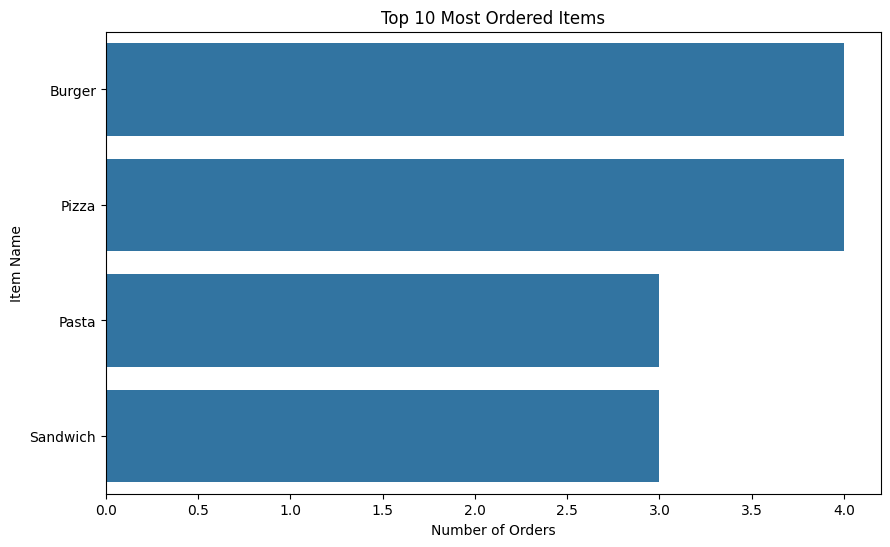

In [29]:
#Top 10 most ordered items
top_items = df['item_name'].value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_items.values, y=top_items.index)
plt.title('Top 10 Most Ordered Items')
plt.xlabel('Number of Orders')
plt.ylabel('Item Name')
plt.show()

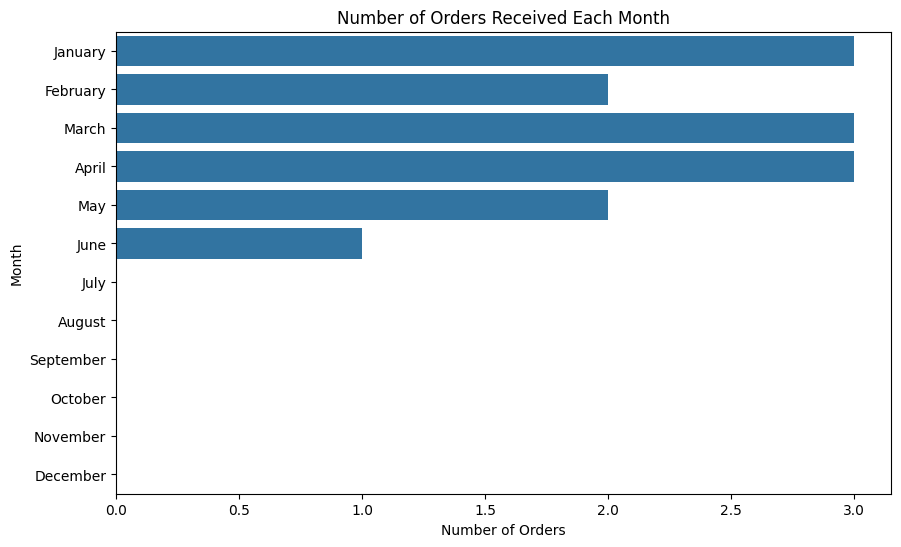

In [30]:
# number of orders received each month
orders_by_month = df['month'].value_counts().reindex([
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
])
plt.figure(figsize=(10,6))
sns.barplot(x=orders_by_month.values, y=orders_by_month.index)
plt.title('Number of Orders Received Each Month')
plt.xlabel('Number of Orders')
plt.ylabel('Month')
plt.show()

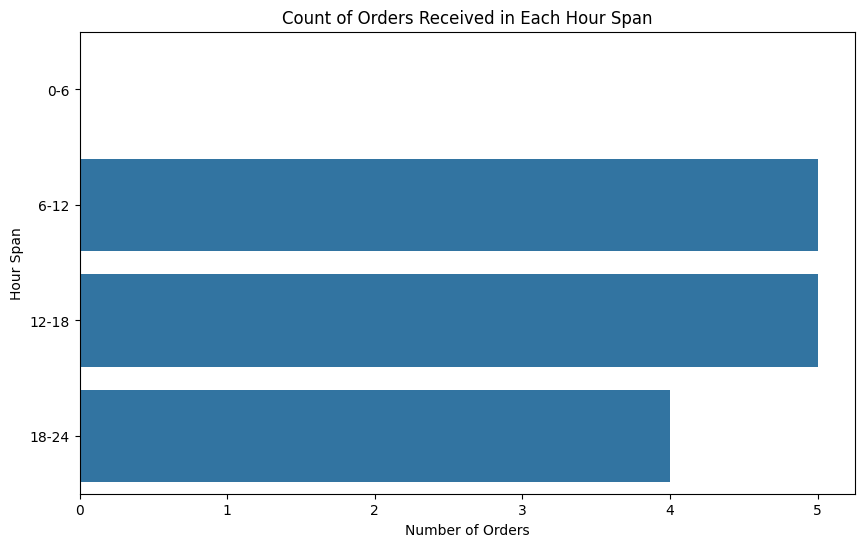

In [31]:
#Count of orders received in each hour_span
orders_by_hour_span = df['hour_span'].value_counts().reindex(['0-6', '6-12', '12-18', '18-24'])
plt.figure(figsize=(10,6))
sns.barplot(x=orders_by_hour_span.values, y=orders_by_hour_span.index)
plt.title('Count of Orders Received in Each Hour Span')
plt.xlabel('Number of Orders')
plt.ylabel('Hour Span')
plt.show()

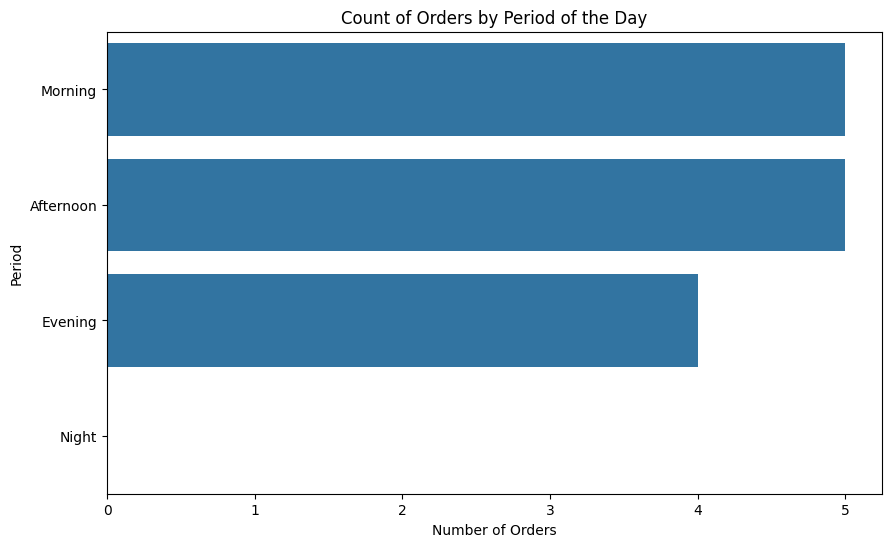

In [33]:
#Count of orders by period of the day 
df['period'] = df['hour'].apply(lambda x: 'Morning' if 6 <= x < 12 else ('Afternoon' if 12 <= x < 18 else ('Evening' if 18 <= x < 24 else 'Night')))    
periods = ['Morning', 'Afternoon', 'Evening', 'Night']
orders_by_period = df['period'].value_counts().reindex(periods)
plt.figure(figsize=(10,6))
sns.barplot(x=orders_by_period.values, y=orders_by_period.index)
plt.title('Count of Orders by Period of the Day')
plt.xlabel('Number of Orders')
plt.ylabel('Period')
plt.show()

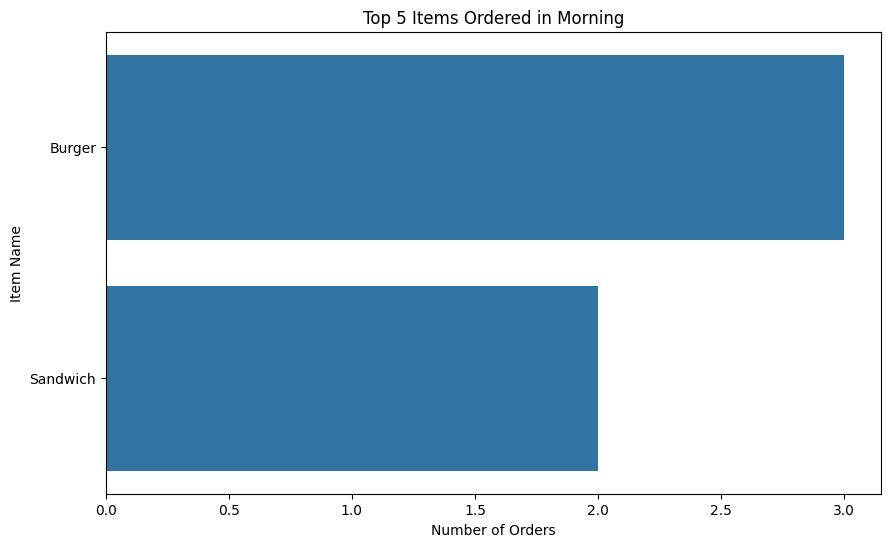

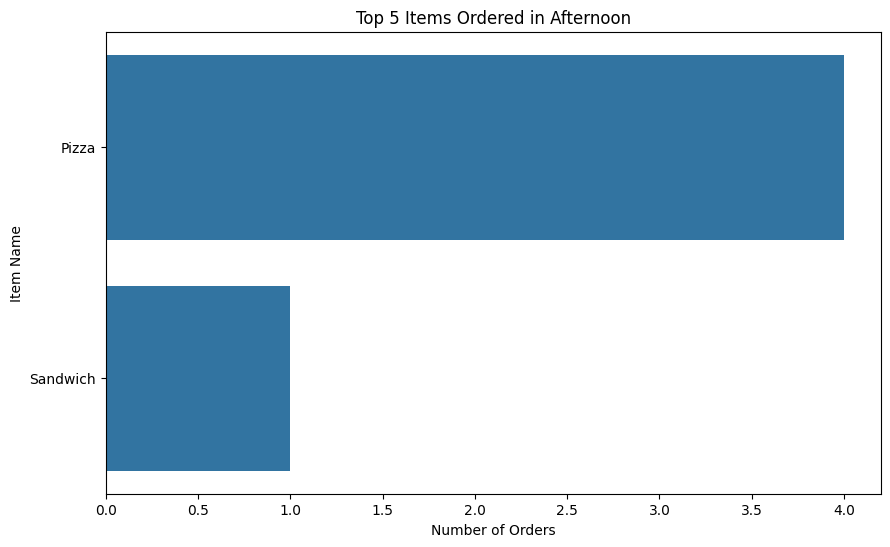

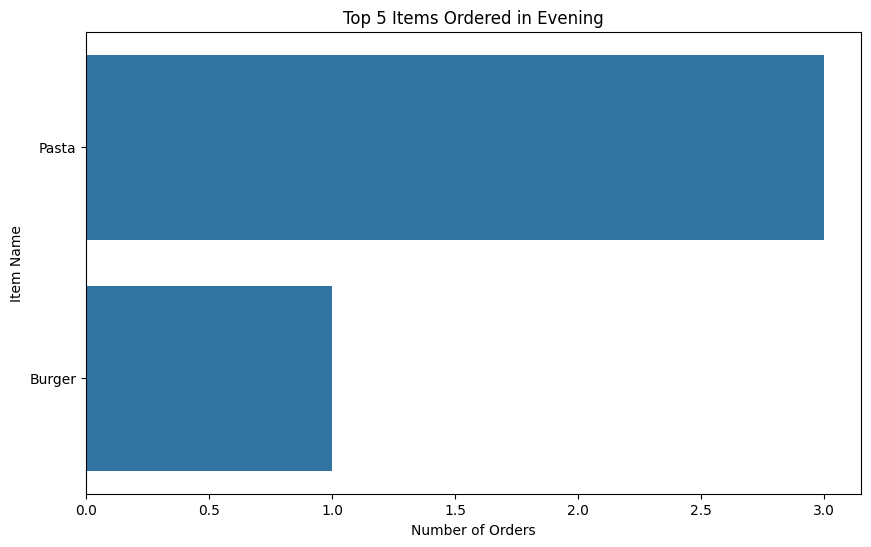

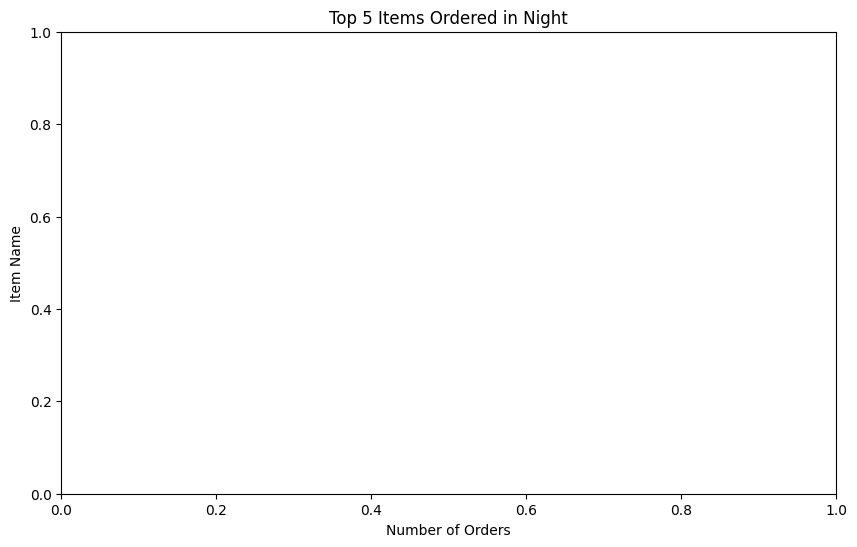

In [34]:
# Top 5 items ordered in each period of the day
for period in periods:
    top_items_period = df[df['period'] == period]['item_name'].value_counts().head(5)
    plt.figure(figsize=(10,6))
    sns.barplot(x=top_items_period.values, y=top_items_period.index)
    plt.title(f'Top 5 Items Ordered in {period}')
    plt.xlabel('Number of Orders')
    plt.ylabel('Item Name')
    plt.show()